# 2. A season on the same street

**Notions:**

- how to play a repeated game whose matrix **changes every day**;
- why a classic strategy like Tit For Tat can **misread** its neighbour;
- how to write a pricing policy that takes the type of day into account.

In [1]:
#import of axelrod can take 18 sec. !
import axelrod as axl
import numpy as np
import matplotlib.pyplot as plt
from bikes import *

## 2.1 Two kinds of towns

The renters meet every day, for a season of 26 weeks. What changes from one town to another is when the busy days come:

| Town | Monday to Friday | Saturday and Sunday |
|---|---|---|
| **active city** | busy (commuters, business visitors) | quiet |
| **tourist town** | quiet | busy (day trippers) |

`season(week)` repeats a week pattern 26 times.

In [2]:
print("active city :", CITY_WEEK)
print("tourist town:", TOURIST_WEEK)
city, tourist = season(CITY_WEEK), season(TOURIST_WEEK)
print(len(city), "days in a season")

active city : ['busy', 'busy', 'busy', 'busy', 'busy', 'quiet', 'quiet']
tourist town: ['quiet', 'quiet', 'quiet', 'quiet', 'quiet', 'busy', 'busy']
182 days in a season


---
## 2.2 Playing a season

In tutorials, you see that `axl.Match` plays one fixed matrix.  
Here the matrix depends on the day, so in `bikes.py` there is the function `play_season(me, neighbour, calendar)`.  
Each day, it:
1. tells both players the type of the day (`self.today`) and keeps the past days (`self.days`);
2. asks each player for its move (`strategy`);
3. scores the day with the quiet-day or the busy-day matrix.

It returns one row per day: my revenue and my neighbour's revenue.  

A player of `play_season` must be a **`Renter`**: the class of `bikes.py` that adds these two (`today` and `days`) attributes to an axelrod `Player`.  
```python
#use:
class MyPolicy(Renter):                 # a new policy: just indicate `name` and write `strategy(self, opponent)`
class MyGrudger(Renter, axl.Grudger):   # copy an existing axelrod strategy, turned into a renter
```
Three axelrod strategies have been turned into renters for this practical work:

| Policy | axelrod strategy | Rule |
|---|---|---|
| `Steady` | `Cooperator` | always the usual price |
| `Opportunist` | `Defector` | always plays the day (undercuts when quiet, surges when busy) |
| `Reciprocal` | `TitForTat` | copies the neighbour's last move |

In [3]:
# example of a season with a steady player and an opportunist player in a tourist town
result = play_season(Steady(), Opportunist(), tourist)
print(result[:10])  # first 10 days

[[  0. 200.]
 [  0. 200.]
 [  0. 200.]
 [  0. 200.]
 [  0. 200.]
 [300. 250.]
 [300. 250.]
 [  0. 200.]
 [  0. 200.]
 [  0. 200.]]


In [4]:
#sum on axis 0 to sum the columns and get the total revenue for each player (axis 1 would sum the rows and give the total revenue for each day)
print("season revenue (me, neighbour):", result.sum(axis=0))

season revenue (me, neighbour): [15600. 39000.]


In `bike.py`, you have the fonction `plot_season(result, names=(X-AXIS, Y-AXIS), title=THE_TITLE)`to plot the cumulative revenue of each player.

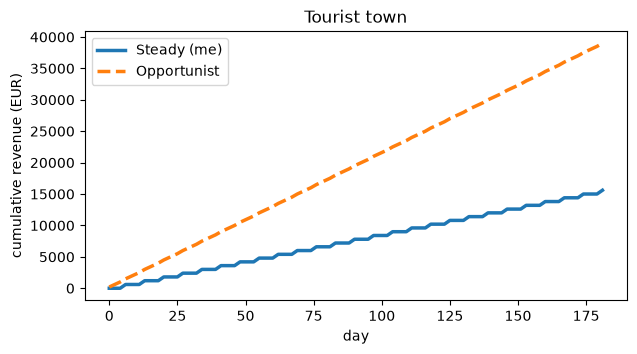

In [5]:
plot_season(result, names=("Steady (me)", "Opportunist"), title="Tourist town")
plt.show()

> **Reading.**  
> In the tourist town, five days out of seven are quiet: the Opportunist undercuts and takes all the customers, while the Steady renter earns nothing on those days.  
> On weekends, the Opportunist surges alone and pays for it in bad reviews, but that does not make up for the weekdays.

**Exercise 1**.   
- Play a season in the tourist town between `Reciprocal()` and `Opportunist()`, 
- then between `Reciprocal()` and `Reciprocal()`. 
- Print the season revenues. 
- Is reciprocity enough to protect you against the Opportunist?

In [6]:
# Exercise 1: your code here

Reciprocal vs Opportunist : me 31620 EUR, neighbour 31820 EUR, balance -200 EUR
Reciprocal vs Reciprocal  : me 35100 EUR, neighbour 35100 EUR, balance 0 EUR


Against the Opportunist, the Reciprocal renter is exploited only once, then undercuts too: both end up in the price war.  
Two Reciprocal renters keep the usual price all season and earn more.  
This is the classic behaviour seen in the iterated prisoner's dilemma.

---

## 2.3 When Tit For Tat misreads its neighbour

Now consider a neighbour who surges on busy days, but never starts a price war on quiet days.

After two players having play a set of games, the function `show_moves(playerA, playerB, nb )` prints the details of the nb first days:
- type of day (`B` = busy, `q` = quiet); 
- name of strategy and move (`C` = usual price, `D` = playing the day) for each player.

In [7]:
# simple strategy: surge on busy days, otherwise cooperate
class SurgeOnBusyDays(Renter):
    name = "Surge on busy days"

    def strategy(self, opponent):
        if self.today == "busy":
            return D
        return C

me = Reciprocal()
neighbour = SurgeOnBusyDays()

play_season(me, neighbour, tourist)

show_moves(me, neighbour, n_days=21)

   day (B=busy, q=quiet)  qqqqqBBqqqqqBBqqqqqBB
              Reciprocal  CCCCCCDDCCCCCDDCCCCCD
      Surge on busy days  CCCCCDDCCCCCDDCCCCCDD


> **Reading.**  
> On Saturday, the neighbour surges to 25 EUR.  
> On Sunday, Tit-For-Tat copies this `D`.  
> On Monday, a quiet day, it copies the Sunday `D` again, but on a quiet day `D` means **undercutting**:  
> -> *Tit-For-Tat steals the Monday customers from a neighbour who never undercut*.   
> This happens every week.

*The problem is that a `D` does not mean the same thing on every day*.   
A surge on a busy day is not an attack; an undercut on a quiet day is.  
A good policy must **interpret a move in the context of the day** it was played.

---

**Exercise 2**.  
Write a policy `MyDayAware`:
- on a busy day, it surges (`D`);
- on a quiet day, it copies the neighbour's **last move on a quiet day** (and plays `C` if there was no quiet day yet).

> *Hint:* 
> - write `class MyDayAware(Renter):` with a `name` and a method `strategy(self, opponent)` (like `SurgeOnBusyDays`);
> - `self.today` is the the types the current day, 
> - `self.days` is the list of the types of past days, 
> - `opponent.history` is the list of moves for each past days
> in python, `for (move, day) in zip(opponent.history, self.days):` gives a tuple (opponent move, type of day)  
> So `[m for (m, d) in zip(opponent.history, self.days) if d == "quiet"]` is the list of the neighbour's quiet-day moves.

Check it against `SurgeOnBusyDays()` with `show_moves`: it should never start a price war.

In [9]:
# Exercise 2: your code here

In [ ]:
me, neighbour = MyDayAware(), SurgeOnBusyDays()
play_season(me, neighbour, tourist)
show_moves(me, neighbour, n_days=21)

   day (B=busy, q=quiet)  qqqqqBBqqqqqBBqqqqqBB
            My day-aware  CCCCCDDCCCCCDDCCCCCDD
      Surge on busy days  CCCCCDDCCCCCDDCCCCCDD


**This policy is available in `bikes.py` as `DayAware`. **  
It surges on busy days whatever the neighbour does, which is risky: surging **alone** brings bad reviews.  
A more prudent idea is to follow the neighbour on each type of day.

---

**Exercise 3**.   
- Write a policy `MyMirror` that copies the neighbour's last move **on the same type of day** as today (`C` the first time).   
- Play it against `DayAware()` in the tourist town and show the first 21 days.

In [11]:
# Exercise 3: your code here

In [ ]:
me, neighbour = MyMirror(), DayAware()
play_season(me, neighbour, tourist)
show_moves(me, neighbour, n_days=21)

   day (B=busy, q=quiet)  qqqqqBBqqqqqBBqqqqqBB
               My mirror  CCCCCCDCCCCCDDCCCCCDD
               Day-aware  CCCCCDDCCCCCDDCCCCCDD


- The first Saturday, the Mirror keeps its usual price and the Day-aware neighbour surges alone.  
- From Sunday on, the Mirror follows: both surge on busy days and both keep the usual price on quiet days.  
- They coordinate **without any agreement**, just by reading each other's moves day type by day type.

---

**Exercise 4**.  
- Play a season of `Mirror()` against `DayAware()` in the **active city** and in the **tourist town**.
- On one plot, draw **your** cumulative revenue in each town (you can use `np.cumsum(result[:, 0])`), 
- and print both season totals. 
- In which town does the season bring in more money, and why?

In [22]:
#example of `np.cumsum(result[:, 0])`), 
result = np.array([[150., 150.], [150., 150.], [150., 150.], [150., 150.], [150., 150.], [300., 250.], [360., 360.], [150., 150.], [150., 150.], [150., 150.],[150., 150.]])
np.cumsum(result[:, 0])

array([ 150.,  300.,  450.,  600.,  750., 1050., 1410., 1560., 1710.,
       1860., 2010.])

In [23]:
# Exercise 4: your code here


Active city   my season revenue: 54540 EUR
Tourist town  my season revenue: 38160 EUR


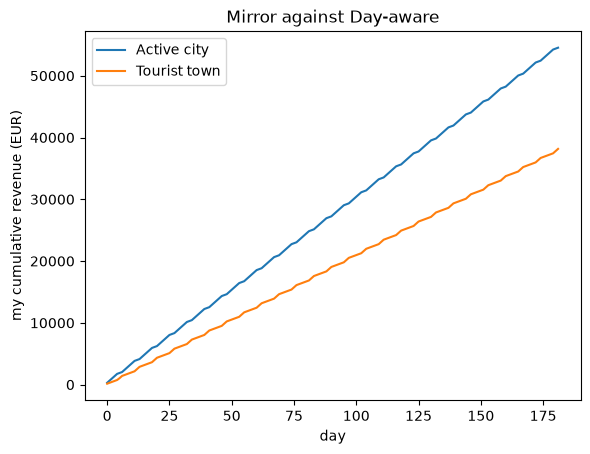

In [ ]:
plt.xlabel("day"); plt.ylabel("my cumulative revenue (EUR)"); plt.title("Mirror against Day-aware")
plt.legend(); plt.show()

The active city has five busy days a week instead of two: once both renters coordinate on 25 EUR, every busy day brings 360 EUR to each, against 150 EUR on a quiet day at the usual price.  
The **same pair of policies** earns much more in the active city: the calendar matters as much as the policy.

---

## Key points

- When the matrix changes from day to day, the same move (`D`) can mean different things: a surge is not an attack.
- A classic strategy that ignores the context (Tit For Tat) can start a price war by mistake.
- A policy can **condition on the type of day**: `self.today` and `self.days`.
- Coordination on high prices can emerge without any agreement, simply by following the neighbour.

But which policy should a renter **choose**, without knowing the neighbour's policy in advance? 